In [1]:
suppressPackageStartupMessages(library(DESeq2))

In [2]:
PAPER_FILTERED_GENES <- 16581
EDGER_SIG_GENES        <- 5127

author_df <- read.delim("../data/GSE117588_organoids-gene-counts.tsv.gz", check.names = FALSE, row.names = 1)
counts <- as.matrix(author_df)

metadata <- read.csv("../metadata/samples.csv", check.names = FALSE)
metadata <- metadata[match(colnames(counts), metadata$count_column), ]
rownames(metadata) <- metadata$count_column
stopifnot(identical(rownames(metadata), colnames(counts)))

#Setting up E3E3_ISO as reference
metadata$group <- factor(metadata$group, levels = c("E3E3_ISO", "E4E4_CTR"))

In [3]:
#Calculating CPM manually (Dividing by the total library size and multiplying it by 1e6)
cpm_calc <- apply(counts, 2, function(x) (x/sum(x))*1000000 )

#Filtering the rows based on cpm values
keep <- rowSums(cpm_calc >= 1) >= 3

#Checking if it is the same as paper filtered gene counts
stopifnot(sum(keep) == PAPER_FILTERED_GENES)

dds <- DESeqDataSetFromMatrix(countData = counts, colData = metadata, design = ~group)
dds <- dds[keep, ]
stopifnot(nrow(dds) == PAPER_FILTERED_GENES)

dds <- DESeq(dds)
resultsNames(dds)
sizeFactors(dds)

res <- results(dds, name = "group_E4E4_CTR_vs_E3E3_ISO", alpha = 0.05, independentFiltering = FALSE, cooksCutoff = FALSE)
summary(res, alpha = 0.05)
stopifnot(nrow(res) == PAPER_FILTERED_GENES)

#Writing res file into a csv and saving in results folder
res_df <- as.data.frame(res)
res_df <- cbind(gene_id = rownames(res_df), res_df)
out_dir <- "../results"
dir.create(out_dir, recursive = TRUE, showWarnings = FALSE)

write.csv(
  res_df,
  file = file.path(out_dir, "deseq2_results.csv"),
  row.names = FALSE
)

deseq_sig <- rownames(res)[!is.na(res$padj) & res$padj < 0.05]
deseq_up <- rownames(res)[!is.na(res$padj) & res$padj < 0.05 & res$log2FoldChange > 0]
deseq_down <- rownames(res)[!is.na(res$padj) & res$padj < 0.05 & res$log2FoldChange < 0]

print(sum(is.na(res$padj)))

print(length(deseq_sig))
print(length(deseq_up))
print(length(deseq_down))
stopifnot(length(deseq_sig) == length(deseq_up) + length(deseq_down))

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



[1] "Intercept"                  "group_E4E4_CTR_vs_E3E3_ISO"

ADR_11    ADR_12    ADR_13    ADR_14     ADR_5     ADR_6 
0.9996069 0.8710526 1.0618680 1.1422108 0.9781083 0.9959981


out of 16581 with nonzero total read count
adjusted p-value < 0.05
LFC > 0 (up)       : 2124, 13%
LFC < 0 (down)     : 2424, 15%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 0)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results

[1] 0
[1] 4548
[1] 2124
[1] 2424


[1] "Pearson r:  0.99973"
[1] "Spearman r: 0.99999"


pdf 
  2

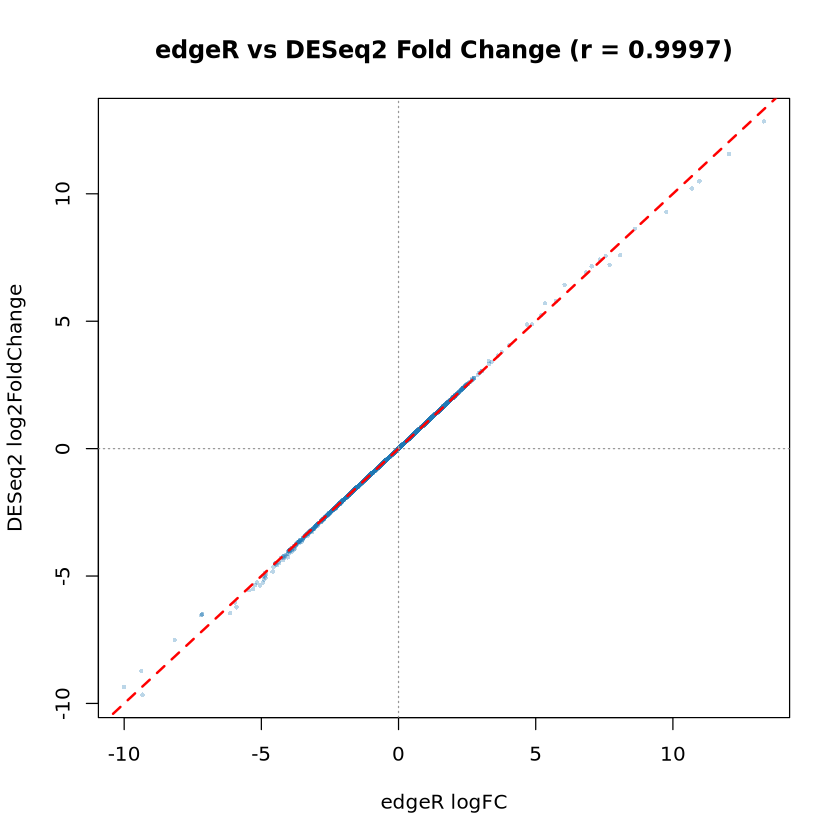

In [6]:
#Loading edgeR results for comparison
edgeR_df <- read.csv("../results/edger_results.csv", check.names = FALSE)
deseq2_df <- read.csv("../results/deseq2_results.csv", check.names = FALSE)

merged_df <- merge(
  edgeR_df,
  deseq2_df,
  by = "gene_id",
  suffixes = c("_edger", "_deseq")
)
stopifnot(nrow(merged_df) == PAPER_FILTERED_GENES)

#Calculating fold changes
pearson_r <- cor(merged_df$logFC, merged_df$log2FoldChange, method="pearson")
spearman_r <- cor(merged_df$logFC, merged_df$log2FoldChange, method="spearman")

print(paste0("Pearson r:  ", round(pearson_r, 5)))
print(paste0("Spearman r: ", round(spearman_r, 5)))


draw_edgeR_DESeq2_comparison <- function() {
  par(bg = "white")
plot(
  merged_df$logFC,
  merged_df$log2FoldChange,
  pch = 16,
  cex = 0.5,
  col = rgb(0.12, 0.47, 0.71, alpha = 0.3),
  xlab = "edgeR logFC",
  ylab = "DESeq2 log2FoldChange",
  main = paste0("edgeR vs DESeq2 Fold Change (r = ", round(pearson_r, 4), ")")
)
}

draw_edgeR_DESeq2_comparison()
#Scatter plot


png(file.path("../images", "edgeR_DESeq2_comparison.png"),
    width = 7, height = 7, units = "in", res = 300, bg = "white")
draw_edgeR_DESeq2_comparison()   # saves to file
dev.off()


# Add 1:1 identity line (y = x) and zero reference axes
abline(a = 0, b = 1, col = "red", lwd = 2, lty = 2)
abline(h = 0, v = 0, col = "gray60", lty = 3)